# Recurrent Neural Network (RNN) Example: Forecasting Daily Temperature

**Background**<br>
Highway agencies need road-temperature forecasts for frost/ice warnings, pavement design, and correcting falling-weight-deflectometer data. Temperature is a **sequence**: tomorrow depends on the recent past. An RNN keeps a **hidden state** — a running memory — updated one day at a time, which is exactly what a fixed-window MLP cannot do.

$$\mathbf{h}_t = \tanh(\mathbf{W}_x \mathbf{x}_t + \mathbf{W}_h \mathbf{h}_{t-1} + \mathbf{b})$$

**Dataset**<br>
26 years (2000–2025) of daily maximum temperature at St. Louis Lambert International Airport (station USW00013995), measured by the U.S. National Weather Service and distributed by NOAA NCEI. 9,497 days. Real weather is partly unpredictable. We will judge the RNN against naive baselines, not a perfect curve.

NOAA National Centers for Environmental Information, *Daily Summaries* dataset, station USW00013995, retrieved via the NCEI Data Service API. Shipped as `Data/stlouis_daily_tmax.csv`.

## The training loop

A training loop usually goes through the following five steps:

```python
optimizer.zero_grad()       # 1. forget the gradients from the previous step
y_hat  = model(x)           # 2. forward pass: make a prediction
loss   = loss_fn(y_hat, y)  # 3. measure how wrong we are
loss.backward()             # 4. backpropagation: compute gradients
optimizer.step()            # 5. update the weights a little
```

Only three things change between architectures: 
- the data
- the model (`nn.Module`) 
- the loss function

## Recurrent Neural Network

Give the network **14 days of history**, ask for **day 15**. `nn.RNN` reads the 14 days one at a time and returns the hidden state at **every** day; we read out only the **last** one and map it to tomorrow's temperature. Tensor convention: **(batch, time, features)**.

In [1]:
import torch                        # PyTorch: tensors + autograd
import torch.nn as nn               # neural-network building blocks (layers, losses)
import pandas as pd                 # read the CSV, inspect the data
import matplotlib.pyplot as plt     # plotting

torch.manual_seed(355)              # reproducibility: same "random" numbers every run
print("PyTorch version:", torch.__version__)

PyTorch version: 2.12.1


### 1. Load the station record and build sliding windows

Each training sample is a window of 14 consecutive days (input) paired with the next day (target). We slide the window one day at a time over the whole record — 9,483 overlapping samples from 9,497 days. Standardization uses training statistics only: never peek at the future.

In [2]:
temp = pd.read_csv("Data/stlouis_daily_tmax.csv")   # daily max temp (deg C)
print(temp.shape, "|", temp["DATE"].iloc[0], "to", temp["DATE"].iloc[-1])
series = torch.tensor(temp["TMAX"].values, dtype=torch.float32).unsqueeze(1)  # (n_days, 1)

WINDOW = 14                                         # two weeks of history
xs, ys = [], []
for i in range(len(series) - WINDOW):
    xs.append(series[i:i+WINDOW])                   # 14 past days -> input
    ys.append(series[i+WINDOW])                     # day 15 -> target
X, y = torch.stack(xs), torch.stack(ys)             # (n, 14, 1), (n, 1) = (batch, time, features)

split = int(0.8 * len(X))                           # first 80% of time = train, last 20% = test
mu, sd = X[:split].mean(), X[:split].std()          # train stats ONLY (no peeking at the future)
X, y = (X - mu) / sd, (y - mu) / sd                 # z-score with those stats
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]
print("X:", X.shape, "-> sequences of 14 days, 1 feature each")

(9497, 3) | 2000-01-01 to 2025-12-31
X: torch.Size([9483, 14, 1]) -> sequences of 14 days, 1 feature each


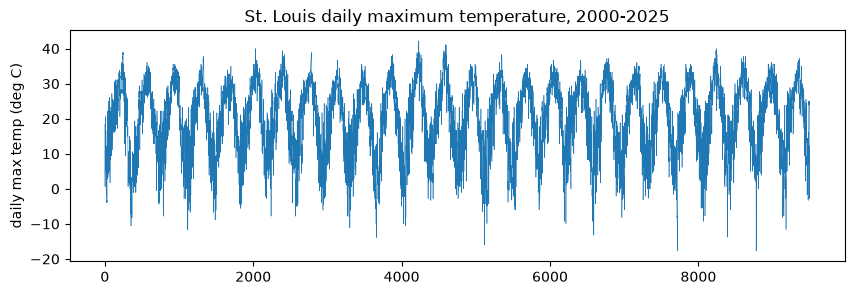

In [3]:
# what the network has to learn: the seasonal wave (plus weekly wiggles and noise)
plt.figure(figsize=(10, 3))
plt.plot(series, lw=0.4)
plt.ylabel("daily max temp (deg C)")
plt.title("St. Louis daily maximum temperature, 2000-2025")
plt.show()

### 2. Build the RNN model

`nn.RNN(input_size=1, hidden_size=32)` — the hidden state is a 32-number memory updated each day. The `head` maps the last hidden state to tomorrow's temperature.

In [4]:
class TempRNN(nn.Module):            # every PyTorch model subclasses nn.Module
    def __init__(self):              # constructor: CREATE the layers here
        super().__init__()           # required: initialize the base class
        self.rnn  = nn.RNN(input_size=1, hidden_size=32, batch_first=True)  # input (batch, time, 1)
        self.head = nn.Linear(32, 1) # 32 hidden numbers -> tomorrow's temperature
    def forward(self, x):            # how data flows; model(x) calls this automatically
        out, h_n = self.rnn(x)       # out: hidden state at EVERY day, shape (batch, 14, 32)
        return self.head(out[:, -1, :])   # use only the LAST day's memory -> (batch, 1)

model = TempRNN()                    # build the network (weights start random)
loss_fn   = nn.MSELoss()             # squared error (regression, like Example 1)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)  # updates all weights; lr = step size

### 3. Train the model

**Full-batch** training like Example 1 — all ~7,500 training windows in one pass. An *epoch* is one full pass over the training data.

In [5]:
for epoch in range(150):                   # full-batch: all training windows at once
    optimizer.zero_grad()                  # 1. forget the gradients from the previous step
    y_hat = model(X_train)                 # 2. forward pass: 14 days in, tomorrow out
    loss  = loss_fn(y_hat, y_train)        # 3. measure how wrong we are (MSE, standardized)
    loss.backward()                        # 4. backprop through TIME: gradients flow day by day
    optimizer.step()                       # 5. update all weights a small step downhill
    if (epoch + 1) % 10 == 0:              # print progress every 10 epochs
        print(f"epoch {epoch+1:3d} | train MSE = {loss.item():.4f}")

epoch  10 | train MSE = 0.2783
epoch  20 | train MSE = 0.2007
epoch  30 | train MSE = 0.1853
epoch  40 | train MSE = 0.1794
epoch  50 | train MSE = 0.1749
epoch  60 | train MSE = 0.1739
epoch  70 | train MSE = 0.1728
epoch  80 | train MSE = 0.1731
epoch  90 | train MSE = 0.1747
epoch 100 | train MSE = 0.1729
epoch 110 | train MSE = 0.1722
epoch 120 | train MSE = 0.1715
epoch 130 | train MSE = 0.1711
epoch 140 | train MSE = 0.1796
epoch 150 | train MSE = 0.1735


### 4. Evaluate on the unseen test years

Real forecasting is judged against baselines, not perfection:
- **Persistence**: predict tomorrow = today.
- **Climatology**: predict the historical average for that day-of-year (from training years only).

If the RNN cannot beat these, it has not learned anything useful.

RNN forecast  RMSE = 4.45 deg C
persistence   RMSE = 4.76 deg C
climatology   RMSE = 5.77 deg C


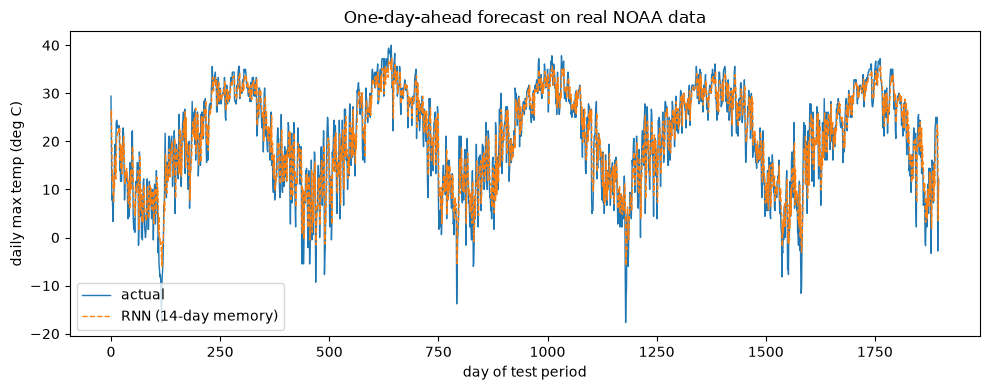

In [6]:
model.eval()                               # evaluation mode
with torch.no_grad():                      # no gradients needed for evaluation
    pred   = model(X_test).squeeze() * sd + mu     # predictions, undo the z-score
    actual = y_test.squeeze() * sd + mu            # true temps, undo the z-score

# baseline 1: persistence (tomorrow = today)
tmax = temp["TMAX"].values
persist = torch.tensor(tmax[WINDOW+split-1:-1], dtype=torch.float32)
# baseline 2: day-of-year climatology, built from TRAINING years only
train_dates = temp["DATE"][:split+WINDOW] # training dates (for climatology)
doy = pd.to_datetime(train_dates).dt.dayofyear.values # day-of-year for each training day
clim_map = pd.Series(tmax[:split+WINDOW]).groupby(doy).mean()   # average per calendar day
doy_test = pd.to_datetime(temp["DATE"][split+WINDOW:]).dt.dayofyear.values # day-of-year for each test day
clim = torch.tensor(clim_map.reindex(doy_test).values, dtype=torch.float32) # climatology for each test day

rmse = lambda p: torch.sqrt(((p - actual)**2).mean()).item()    # root mean squared error
print(f"RNN forecast  RMSE = {rmse(pred):.2f} deg C")
print(f"persistence   RMSE = {rmse(persist):.2f} deg C")
print(f"climatology   RMSE = {rmse(clim):.2f} deg C")

plt.figure(figsize=(10, 4))
plt.plot(actual, label="actual", lw=1)
plt.plot(pred, "--", label="RNN (14-day memory)", lw=1)
plt.xlabel("day of test period"); plt.ylabel("daily max temp (deg C)")
plt.legend(); plt.title("One-day-ahead forecast on real NOAA data")
plt.tight_layout(); plt.show()

**Check** <br>
The RNN beats both baselines because it has learned the *seasonal phase* — where in the year we are — which persistence ignores and climatology approximates coarsely. The remaining error (~2–3 °C) is day-to-day weather chaos that a 14-day memory cannot resolve.

**Exercises**
1. Try `WINDOW = 3` vs `WINDOW = 30`. Which tracks the seasons better?
2. Replace `nn.RNN` with `nn.LSTM` (same constructor arguments). Any improvement on real data?
3. Fetch temperature for **your own city**: change the station ID in `make_data.py` (find stations at ncei.noaa.gov) and rerun. Does the RMSE change?
